<a href="https://colab.research.google.com/github/Oleksandr-123/practice-1/blob/main/notebooks/PR03_%D0%9C%D0%B0%D1%81%D0%BB%D0%B0%D0%BA_%D0%A1%D0%B0%D1%88%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Практична робота 3
## Перша модель і базове оцінювання якості

**Дисципліна:** Розпізнавання образів і машинне навчання

**Студент:** Маслак Олександр

**Група:** ІН-42/1

**Дата виконання:** 17.11.2026

### Мета роботи

Побудувати першу модель машинного навчання, отримати прогнози та навчитися оцінювати їхню якість за допомогою основних метрик класифікації.


In [ ]:

from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

from IPython.display import display


In [16]:

PROJECT_DIR = Path(
    "/content/drive/MyDrive/pattern-recognition-practice"
)

DATA_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/iris_cleaned.csv"
)

MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODEL_PATH = MODELS_DIR / "iris_decision_tree.joblib"
METRICS_PATH = REPORTS_DIR / "model_metrics.csv"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Файл даних:", DATA_PATH)
print("Файл моделі:", MODEL_PATH)


Файл даних: /content/drive/MyDrive/Colab Notebooks/iris_cleaned.csv
Файл моделі: /content/drive/MyDrive/pattern-recognition-practice/models/iris_decision_tree.joblib


In [21]:
data = pd.read_csv(DATA_PATH)

print("Розмір набору даних:", data.shape)

print("\nПерші п'ять рядків:")
display(data.head())

print("\nНазви стовпців:")
print(data.columns.tolist())

Розмір набору даних: (148, 6)

Перші п'ять рядків:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,5.8,3.0,1.4,0.2,setosa,device_b
2,6.3,3.2,1.3,0.2,setosa,device_c
3,4.6,3.1,1.5,0.2,setosa,device_a
4,5.0,3.6,1.4,0.2,setosa,device_b



Назви стовпців:
['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm', 'species', 'measurement_device']


### Підготовка даних

Для побудови моделі використовуються чотири числові ознаки квітки. Цільовою змінною є вид квітки (species). Стовпець measurement_device не використовується під час навчання.

In [24]:
X = data[
    [
        "sepal_length_cm",
        "sepal_width_cm",
        "petal_length_cm",
        "petal_width_cm"
    ]
]

y = data["species"]

print("Розмір матриці ознак X:", X.shape)
print("Розмір цільової змінної y:", y.shape)

print("\nРозподіл класів:")
print(y.value_counts())

Розмір матриці ознак X: (148, 4)
Розмір цільової змінної y: (148,)

Розподіл класів:
species
setosa        50
versicolor    49
virginica     49
Name: count, dtype: int64


### Розділення даних

Дані поділяються на навчальну та тестову вибірки. Навчальна вибірка використовується для побудови моделі, а тестова — для перевірки її якості.

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

Розмір навчальної вибірки: (118, 4)
Розмір тестової вибірки: (30, 4)


In [26]:
print("Класи у навчальній вибірці:")
print(y_train.value_counts())

print("\nКласи у тестовій вибірці:")
print(y_test.value_counts())

Класи у навчальній вибірці:
species
setosa        40
versicolor    39
virginica     39
Name: count, dtype: int64

Класи у тестовій вибірці:
species
versicolor    10
virginica     10
setosa        10
Name: count, dtype: int64


### Базова модель

Спочатку створюється проста базова модель, яка завжди прогнозує найпоширеніший клас. Вона потрібна для порівняння з основною моделлю.

In [27]:
dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

print("Прогнози базової моделі:")
print(dummy_predictions)

Прогнози базової моделі:
['setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa'
 'setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa'
 'setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa'
 'setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa']


### Оцінювання базової моделі

Для перевірки базової моделі використовуються метрики Accuracy, Precision, Recall та F1-score. Для Precision, Recall і F1-score використовується середнє значення macro.

In [28]:
dummy_accuracy = accuracy_score(y_test, dummy_predictions)

dummy_precision = precision_score(
    y_test, dummy_predictions, average="macro", zero_division=0
)

dummy_recall = recall_score(
    y_test, dummy_predictions, average="macro", zero_division=0
)

dummy_f1 = f1_score(
    y_test, dummy_predictions, average="macro", zero_division=0
)

print("Accuracy:", dummy_accuracy)
print("Precision:", dummy_precision)
print("Recall:", dummy_recall)
print("F1-score:", dummy_f1)

Accuracy: 0.3333333333333333
Precision: 0.1111111111111111
Recall: 0.3333333333333333
F1-score: 0.16666666666666666


### Модель дерева рішень

Створюється модель Decision Tree з максимальною глибиною 3. Вона навчається на навчальній вибірці та використовується для прогнозування видів квітів.

In [29]:
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

print("Прогнози моделі Decision Tree:")
print(tree_predictions)

Прогнози моделі Decision Tree:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica' 'setosa' 'setosa' 'setosa'
 'versicolor' 'virginica' 'setosa' 'versicolor' 'setosa' 'virginica'
 'setosa' 'versicolor' 'virginica' 'versicolor' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'virginica' 'virginica' 'virginica']


### Оцінювання моделі Decision Tree

Якість моделі оцінюється за допомогою Accuracy, Precision, Recall та F1-score. Для Precision, Recall і F1-score використовується середнє значення macro.

In [30]:
tree_accuracy = accuracy_score(y_test, tree_predictions)

tree_precision = precision_score(
    y_test, tree_predictions, average="macro"
)

tree_recall = recall_score(
    y_test, tree_predictions, average="macro"
)

tree_f1 = f1_score(
    y_test, tree_predictions, average="macro"
)

print("Accuracy:", tree_accuracy)
print("Precision:", tree_precision)
print("Recall:", tree_recall)
print("F1-score:", tree_f1)

Accuracy: 0.9333333333333333
Precision: 0.9363636363636364
Recall: 0.9333333333333332
F1-score: 0.933249791144528


### Порівняння моделей

Порівнюються результати базової моделі DummyClassifier та моделі Decision Tree за основними метриками якості.

In [31]:
comparison = pd.DataFrame({
    "Модель": ["DummyClassifier", "Decision Tree"],
    "Accuracy": [dummy_accuracy, tree_accuracy],
    "Precision": [dummy_precision, tree_precision],
    "Recall": [dummy_recall, tree_recall],
    "F1-score": [dummy_f1, tree_f1]
})

display(comparison)

,Модель,Accuracy,Precision,Recall,F1-score
0,DummyClassifier,0.333333,0.111111,0.333333,0.166667
1,Decision Tree,0.933333,0.936364,0.933333,0.933250


### Матриця помилок

Матриця помилок показує, скільки об'єктів кожного класу модель класифікувала правильно та неправильно.

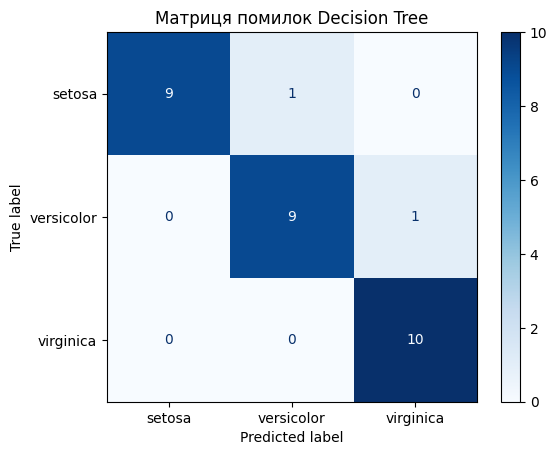

In [32]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tree_predictions,
    cmap="Blues"
)

plt.title("Матриця помилок Decision Tree")
plt.show()

### Аналіз помилок

Перевіряються записи, для яких прогноз моделі не збігається з фактичним класом.

In [33]:
errors = X_test.copy()

errors["Фактичний клас"] = y_test
errors["Прогноз моделі"] = tree_predictions

errors = errors[
    errors["Фактичний клас"] != errors["Прогноз моделі"]
]

print("Кількість помилок:", len(errors))
display(errors)

Кількість помилок: 2


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,Фактичний клас,Прогноз моделі
10,5.4,3.7,4.3,0.2,setosa,versicolor
77,6.7,3.0,5.0,1.7,versicolor,virginica


### Збереження моделі

Навчена модель Decision Tree зберігається у файл за допомогою бібліотеки joblib.

In [34]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(tree_model, MODEL_PATH)

print("Модель збережено:", MODEL_PATH)
print("Файл існує:", MODEL_PATH.exists())

Модель збережено: /content/drive/MyDrive/pattern-recognition-practice/models/iris_decision_tree.joblib
Файл існує: True


### Перевірка завантаження моделі

Збережена модель завантажується з файлу. Перевіряється, чи збігаються її прогнози з початковими прогнозами.

In [35]:
loaded_model = joblib.load(MODEL_PATH)

loaded_predictions = loaded_model.predict(X_test)

print("Прогнози завантаженої моделі:")
print(loaded_predictions)

print(
    "Прогнози збігаються:",
    (loaded_predictions == tree_predictions).all()
)

Прогнози завантаженої моделі:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica' 'setosa' 'setosa' 'setosa'
 'versicolor' 'virginica' 'setosa' 'versicolor' 'setosa' 'virginica'
 'setosa' 'versicolor' 'virginica' 'versicolor' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'virginica' 'virginica' 'virginica']
Прогнози збігаються: True


### Збереження метрик

Результати оцінювання обох моделей зберігаються у CSV-файл для подальшого використання.

In [36]:
metrics = pd.DataFrame({
    "model": ["DummyClassifier", "Decision Tree"],
    "accuracy": [dummy_accuracy, tree_accuracy],
    "precision_macro": [dummy_precision, tree_precision],
    "recall_macro": [dummy_recall, tree_recall],
    "f1_macro": [dummy_f1, tree_f1]
})

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

metrics.to_csv(METRICS_PATH, index=False)

print("Метрики збережено:", METRICS_PATH)
print("Файл існує:", METRICS_PATH.exists())

display(metrics)

Метрики збережено: /content/drive/MyDrive/pattern-recognition-practice/reports/model_metrics.csv
Файл існує: True


,model,accuracy,precision_macro,recall_macro,f1_macro
0,DummyClassifier,0.333333,0.111111,0.333333,0.166667
1,Decision Tree,0.933333,0.936364,0.933333,0.933250


### Перевірка результатів

Виконуються перевірки розмірів вибірок, кількості прогнозів, значень метрик та наявності збережених файлів.

In [37]:
assert len(X_train) + len(X_test) == len(data)
assert len(tree_predictions) == len(y_test)
assert 0 <= tree_accuracy <= 1
assert 0 <= tree_precision <= 1
assert 0 <= tree_recall <= 1
assert 0 <= tree_f1 <= 1
assert MODEL_PATH.exists()
assert METRICS_PATH.exists()

print("Усі перевірки успішно пройдено.")

Усі перевірки успішно пройдено.


### Порівняння навчальної та тестової вибірок

Порівнюється якість моделей на навчальних і тестових даних за метриками Accuracy та F1-score.

In [38]:
train_predictions = tree_model.predict(X_train)

train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, tree_predictions)

train_f1 = f1_score(y_train, train_predictions, average="macro")
test_f1 = f1_score(y_test, tree_predictions, average="macro")

comparison_data = pd.DataFrame({
    "Вибірка": ["Навчальна", "Тестова"],
    "Accuracy": [train_accuracy, test_accuracy],
    "F1-score": [train_f1, test_f1]
})

display(comparison_data)

,Вибірка,Accuracy,F1-score
0,Навчальна,0.983051,0.982895
1,Тестова,0.933333,0.933250


### Візуалізація результатів

На графіку порівнюються значення Accuracy для навчальної та тестової вибірок.

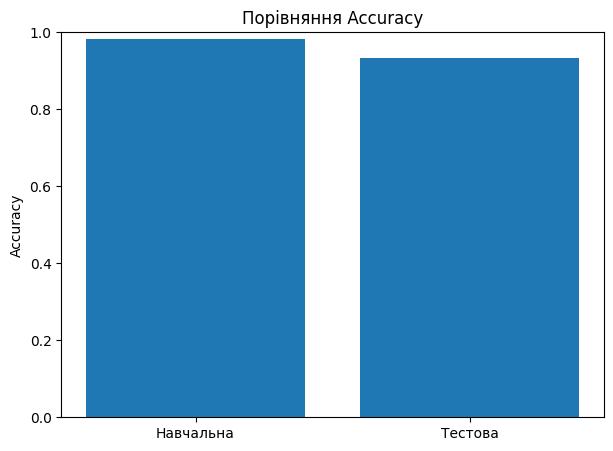

In [39]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison_data["Вибірка"],
    comparison_data["Accuracy"]
)

plt.title("Порівняння Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()

## Висновки

Під час практичної роботи було підготовлено набір даних Iris та створено дві моделі класифікації: DummyClassifier і Decision Tree.

Для оцінювання моделей використовувалися метрики Accuracy, Precision, Recall та F1-score.

Базова модель DummyClassifier отримала Accuracy 0.3333, а модель Decision Tree — 0.9333.

Модель Decision Tree правильно класифікувала 28 із 30 тестових записів. Було виявлено 2 помилки класифікації.

Навчену модель успішно збережено у файл та перевірено після повторного завантаження. Метрики моделей також збережено у CSV-файл.

Отже, модель Decision Tree показала кращий результат порівняно з базовою моделлю.